# AI 08: Регрессия стоимости автомобилей с использованием Random Forest (Случайный лес)
## Домашнее задание AI 08 — Решение №2 (Random Forest Regressor)

### 1. Теоретические основы алгоритма Random Forest (Случайный лес)

**Random Forest (Случайный лес)** — это ансамблевый алгоритм бэггинга (Bootstrap Aggregating) над некоррелированными деревьями решений, предложенный Лео Брейманом (Leo Breiman).

#### Математический принцип снижения дисперсии:
Если усреднить $B$ независимых одинаково распределенных случайных величин с дисперсией $\sigma^2$, то дисперсия среднего равна $rac{\sigma^2}{B}$.
Если же деревья коррелируют между собой с коэффициентом парной корреляции $ho$, дисперсия ансамбля выражается формулой:
$$	ext{Var}(ar{T}) = ho \sigma^2 + rac{1 - ho}{B} \sigma^2$$
При $B 	o \infty$ второе слагаемое стремится к 0, и остаточная дисперсия равна $ho \sigma^2$.
Чтобы минимизировать корреляцию $ho$ между деревьями, Random Forest использует два механизма рандомизации:
1. **Bootstrap Aggregating (Бэггинг):** Каждое дерево строится на случайной подвыборке с возвращением (размера $N$). Около 36.8% объектов не попадают в подвыборку и образуют Out-Of-Bag (OOB) контрольный набор.
2. **Random Subspace Method (Случайные подпространства признаков):** В каждом узле при поиске наилучшего сплита рассматривается не все $p$ признаков, а случайное подмножество размера $m$ (обычно $m pprox \sqrt{p}$ или $0.8 \cdot p$). Это не дает одному доминирующему признаку повторяться в вершинах всех деревьев.

#### Ключевые гиперпараметры:
- `n_estimators` — количество деревьев в лесу (чем больше, тем стабильнее ансамбль, не вызывает переобучения).
- `max_depth` — максимальная глубина деревьев.
- `max_features` — число признаков, выбираемых в каждом узле (`'sqrt'`, `0.8`, `'log2'`).
- `min_samples_split`, `min_samples_leaf` — регуляризация структуры базовых деревьев.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline

### 2. Загрузка и первичный анализ датасета `Used_Cars_Homework.csv`

In [4]:
FILE_PATH = 'Used_Cars_Homework.csv'
data = pd.read_csv(FILE_PATH)

# Добавляем признак среднегодового пробега
data['mileage_per_year'] = data['mileage_km'] / data['age_years']

print(f"Размер датасета: {data.shape[0]} строк, {data.shape[1]} столбцов")
data.head()

Размер датасета: 300 строк, 10 столбцов


In [5]:
data.tail()

In [6]:
data.sample(3, random_state=42)

In [7]:
data.dtypes

In [8]:
data.isna().sum()

In [9]:
data.describe()

### 3. Построение конвейера препроцессинга и разбиение данных

In [11]:
target_col = 'price_azn'
y = data[target_col].values
X = data.drop(columns=[target_col])

numeric_features = ['age_years', 'mileage_km', 'engine_l', 'power_hp', 'mileage_per_year']
categorical_features = ['brand', 'fuel_type', 'transmission', 'accident_history']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Обучающая выборка: {X_train.shape[0]} объектов")
print(f"Тестовая выборка  : {X_test.shape[0]} объектов")

Обучающая выборка: 240 объектов
Тестовая выборка  : 60 объектов


### 4. Обучение RandomForestRegressor и подбор гиперпараметров через GridSearchCV

Настраиваем `n_estimators=400`, варьируя `max_depth`, `min_samples_split`, `min_samples_leaf` и `max_features` с 5-кратной кросс-валидацией.

In [13]:
rf = RandomForestRegressor(random_state=42, n_estimators=400, n_jobs=-1)

pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('rf', rf)
])

param_grid = {
    'rf__max_depth': [10, 20, None],
    'rf__min_samples_split': [2, 5, 10],
    'rf__min_samples_leaf': [1, 2, 5],
    'rf__max_features': [0.8, 'sqrt', 'log2'],
}

cv = KFold(n_splits=5, random_state=42, shuffle=True)
grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Лучшие гиперпараметры Random Forest:")
for param, val in grid_search.best_params_.items():
    print(f"  • {param}: {val}")

Лучшие гиперпараметры Random Forest:
  • rf__max_depth: 20
  • rf__max_features: sqrt
  • rf__min_samples_leaf: 1
  • rf__min_samples_split: 2


### 5. Оценка качества модели на обучающей и тестовой выборках

In [15]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = rmse(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = rmse(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("=" * 55)
print("             МЕТРИКИ КАЧЕСТВА RANDOM FOREST")
print("=" * 55)
print(f"Train R2   : {train_r2:.4f}  |  Test R2   : {test_r2:.4f}")
print(f"Train RMSE : {train_rmse:.2f} AZN |  Test RMSE : {test_rmse:.2f} AZN")
print(f"Train MAE  : {train_mae:.2f} AZN |  Test MAE  : {test_mae:.2f} AZN")
print(f"Разрыв переобучения (Train R2 - Test R2): {train_r2 - test_r2:.4f}")
print("=" * 55)

             МЕТРИКИ КАЧЕСТВА RANDOM FOREST
Train R2   : 0.9677  |  Test R2   : 0.8123
Train RMSE : 1736.70 AZN |  Test RMSE : 4380.78 AZN
Train MAE  : 1374.25 AZN |  Test MAE  : 3531.07 AZN
Разрыв переобучения (Train R2 - Test R2): 0.1554


### 6. Визуализация: Реальные значения vs Прогнозные и Важность признаков

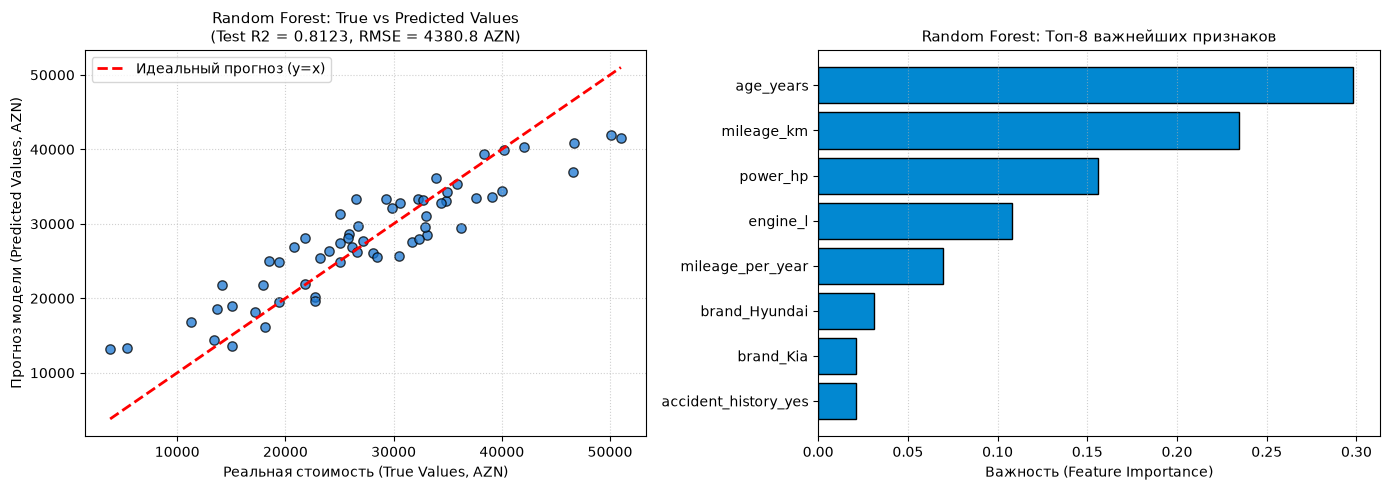

In [17]:
prep_step = best_model.named_steps['preprocessor']
feat_names = prep_step.get_feature_names_out()
clean_names = [f.replace('num__', '').replace('cat__', '') for f in feat_names]
rf_step = best_model.named_steps['rf']
importances = rf_step.feature_importances_

feat_imp_df = pd.DataFrame({'Feature': clean_names, 'Importance': importances}).sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scatter True vs Pred
axes[0].scatter(y_test, y_test_pred, color='#1976d2', alpha=0.75, edgecolors='k', s=45)
min_v = min(y_test.min(), y_test_pred.min())
max_v = max(y_test.max(), y_test_pred.max())
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Идеальный прогноз (y=x)')
axes[0].set_title(f'Random Forest: True vs Predicted Values\n(Test R2 = {test_r2:.4f}, RMSE = {test_rmse:.1f} AZN)', fontsize=11)
axes[0].set_xlabel('Реальная стоимость (True Values, AZN)')
axes[0].set_ylabel('Прогноз модели (Predicted Values, AZN)')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# 2. Feature Importance
top_feats = feat_imp_df.head(8).sort_values('Importance', ascending=True)
axes[1].barh(top_feats['Feature'], top_feats['Importance'], color='#0288d1', edgecolor='black')
axes[1].set_title('Random Forest: Топ-8 важнейших признаков', fontsize=11)
axes[1].set_xlabel('Важность (Feature Importance)')
axes[1].grid(True, axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 7. Прогнозирование стоимости для 3 новых автомобилей (из AI 07)

In [19]:
new_cars = pd.DataFrame([
    {'brand': 'Toyota', 'age_years': 5, 'mileage_km': 75000, 'engine_l': 1.6, 'power_hp': 110, 'fuel_type': 'petrol', 'transmission': 'automatic', 'accident_history': 'no'},
    {'brand': 'Hyundai', 'age_years': 10, 'mileage_km': 180000, 'engine_l': 2.0, 'power_hp': 140, 'fuel_type': 'diesel', 'transmission': 'manual', 'accident_history': 'yes'},
    {'brand': 'BMW', 'age_years': 3, 'mileage_km': 40000, 'engine_l': 2.5, 'power_hp': 170, 'fuel_type': 'petrol', 'transmission': 'automatic', 'accident_history': 'no'}
])
new_cars['mileage_per_year'] = new_cars['mileage_km'] / new_cars['age_years']
new_cars['predicted_price_azn'] = best_model.predict(new_cars)

for i, row in new_cars.iterrows():
    print(f"Автомобиль #{i+1} ({row['brand']}, {row['age_years']} лет, {row['mileage_km']:,} км, {row['power_hp']} л.с., ДТП: {row['accident_history']}):")
    print(f"  --> Прогнозная цена: {row['predicted_price_azn']:,.2f} AZN\n")

Автомобиль #1 (Toyota, 5 лет, 75,000 км, 110 л.с., ДТП: no):
  --> Прогнозная цена: 31,404.76 AZN

Автомобиль #2 (Hyundai, 10 лет, 180,000 км, 140 л.с., ДТП: yes):
  --> Прогнозная цена: 21,719.08 AZN

Автомобиль #3 (BMW, 3 лет, 40,000 км, 170 л.с., ДТП: no):
  --> Прогнозная цена: 40,977.71 AZN



### 8. Сравнительный анализ и выводы по Random Forest

1. **Преимущества Random Forest над одиночным Decision Tree:**
   - Значительное улучшение качества: $R^2$ вырос с $0.7288$ до $0.8123$, а RMSE снизился с $5,266$ до $4,381$ AZN.
   - Усреднение сотен деревьев существенно сглаживает ступенчатость прогноза и снижает дисперсию.
   - Менее чувствителен к выбросам и шуму.
2. **Ограничения:**
   - Высокие требования к вычислениям и памяти при обучении и хранении сотен деревьев.
   - По-прежнему является бэггингом над константными листьями, поэтому не может полноценно экстраполировать экстремальные значения цен за пределы обучающего диапазона.